## Kevin's Section

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [33]:
df = pd.read_csv('data/RRCA_baseflow.csv')

df['Days'] = df['Date'] - 693963
df['DateTime'] = pd.to_datetime("1900-01-01") + pd.to_timedelta(df['Days'], unit='D')
df['Year'] = df['DateTime'].dt.year
df['Month'] = df['DateTime'].dt.month

df

,Date,Segment_id,x,y,Evapotranspiration,Precipitation,Irrigation_pumping,Observed,Days,DateTime,Year,Month
0,710732,144,1086190,14476800,0.59,18.99,0.0,0.145161,16769,1945-11-30,1945,11
1,710763,144,1086190,14476800,0.97,29.63,0.0,0.445161,16800,1945-12-31,1945,12
2,710791,144,1086190,14476800,1.34,29.63,0.0,1.332203,16828,1946-01-28,1946,1
3,710822,144,1086190,14476800,1.79,29.63,0.0,2.932203,16859,1946-02-28,1946,2
4,710852,144,1086190,14476800,8.23,29.63,0.0,3.728689,16889,1946-03-30,1946,3
...,...,...,...,...,...,...,...,...,...,...,...,...
15586,721810,98,721870,14387040,0.00,0.00,0.0,0.298500,27847,1976-03-30,1976,3
15587,721841,98,721870,14387040,0.00,0.00,0.0,0.211475,27878,1976-04-30,1976,4
15588,721871,98,721870,14387040,0.00,0.00,0.0,0.122951,27908,1976-05-30,1976,5
15589,721902,98,721870,14387040,0.00,0.00,0.0,0.120000,27939,1976-06-30,1976,6


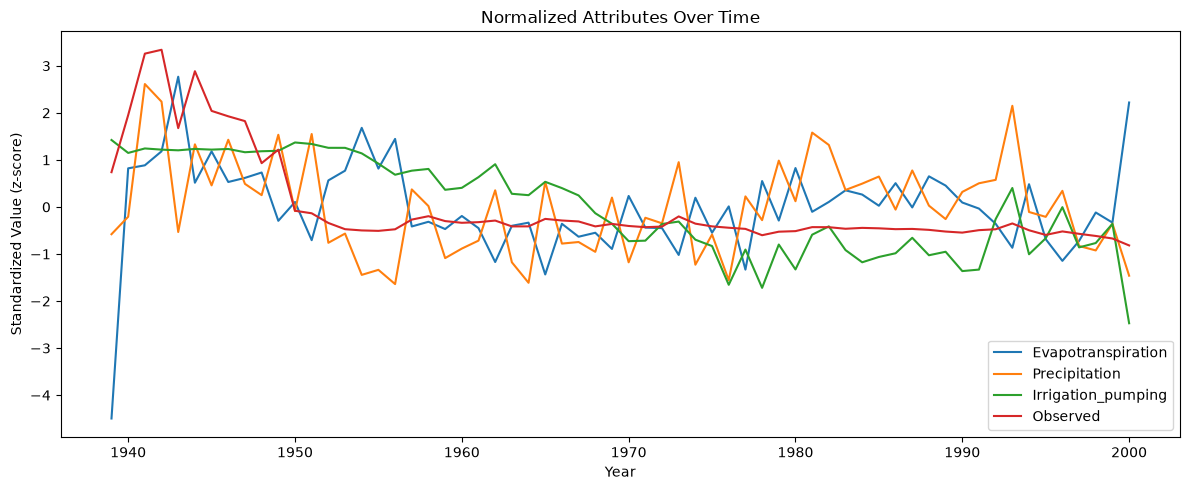

In [34]:
attributes = ["Evapotranspiration", "Precipitation", "Irrigation_pumping", "Observed"]

plt.figure(figsize=(12, 5))
for attr in attributes:
    yearly_avg = df.groupby("Year")[attr].mean()
    normalized = (yearly_avg - yearly_avg.mean()) / yearly_avg.std()
    plt.plot(yearly_avg.index, normalized.values, label=attr)

plt.xlabel("Year")
plt.ylabel("Standardized Value (z-score)")
plt.title("Normalized Attributes Over Time")
plt.legend()
plt.tight_layout()
plt.show()

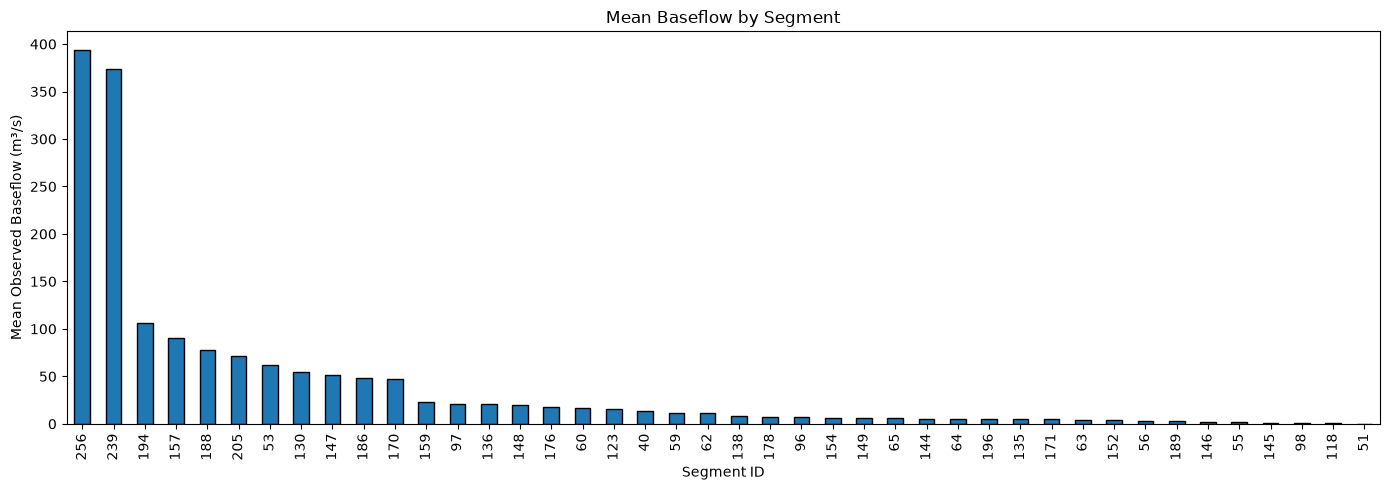

In [35]:
# Which segments have the highest/lowest baseflow
seg_means = df.groupby("Segment_id")["Observed"].mean().sort_values(ascending=False)

plt.figure(figsize=(14, 5))
seg_means.plot(kind="bar", edgecolor="black")
plt.xlabel("Segment ID")
plt.ylabel("Mean Observed Baseflow (m³/s)")
plt.title("Mean Baseflow by Segment")
plt.tight_layout()
plt.show()

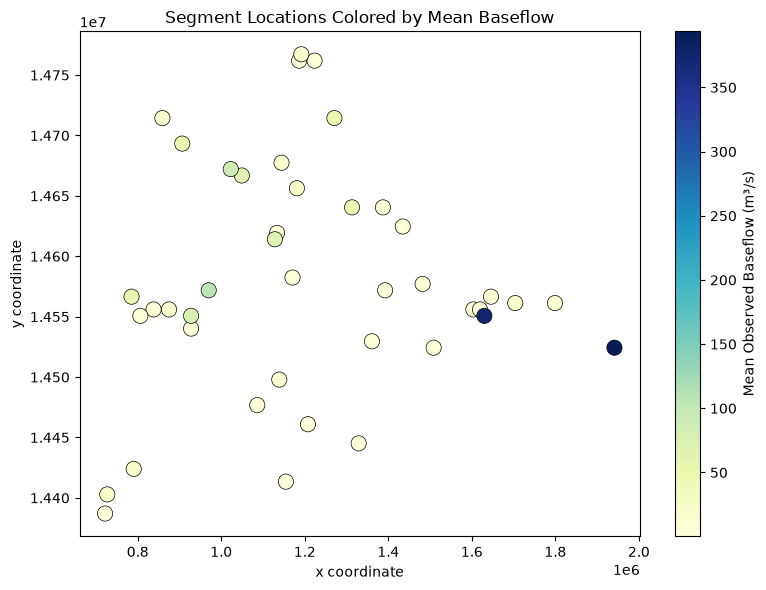

In [36]:
seg_stats = df.groupby("Segment_id").agg(
    x=("x", "first"), y=("y", "first"),
    mean_obs=("Observed", "mean")
).reset_index()

plt.figure(figsize=(8, 6))
sc = plt.scatter(seg_stats["x"], seg_stats["y"], c=seg_stats["mean_obs"],
                 cmap="YlGnBu", s=120, edgecolors="black", linewidth=0.5)
plt.colorbar(sc, label="Mean Observed Baseflow (m³/s)")
plt.xlabel("x coordinate")
plt.ylabel("y coordinate")
plt.title("Segment Locations Colored by Mean Baseflow")
plt.tight_layout()
plt.show()

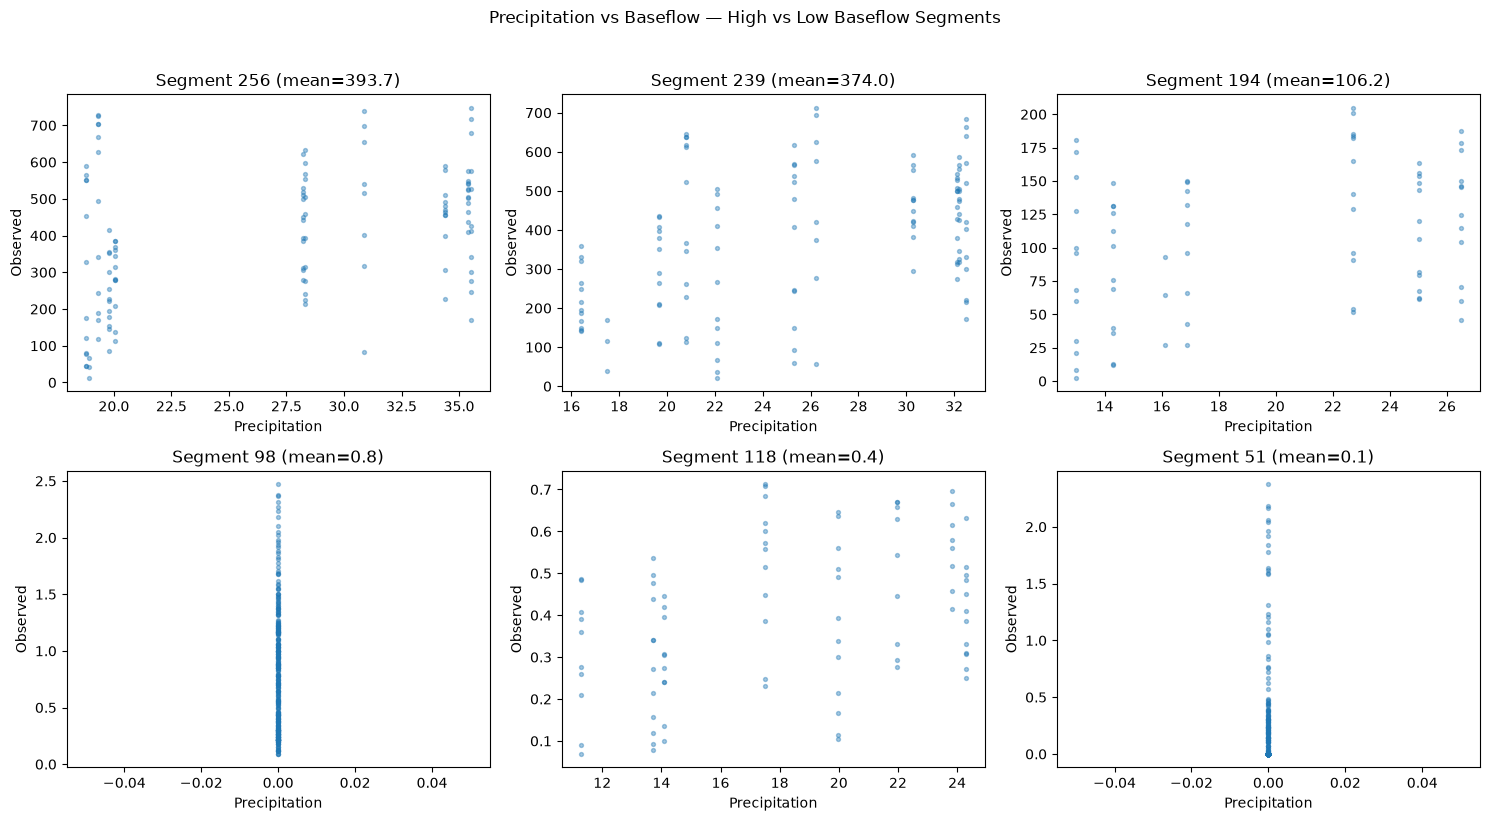

In [37]:
# Pick a few segments with very different mean baseflow
top3 = seg_means.head(3).index.tolist()
bot3 = seg_means.tail(3).index.tolist()
sample = top3 + bot3

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, seg_id in zip(axes.flat, sample):
    sub = df[df["Segment_id"] == seg_id]
    ax.scatter(sub["Precipitation"], sub["Observed"], s=8, alpha=0.4)
    ax.set_title(f"Segment {seg_id} (mean={sub['Observed'].mean():.1f})")
    ax.set_xlabel("Precipitation")
    ax.set_ylabel("Observed")

plt.suptitle("Precipitation vs Baseflow — High vs Low Baseflow Segments", y=1.02)
plt.tight_layout()
plt.show()

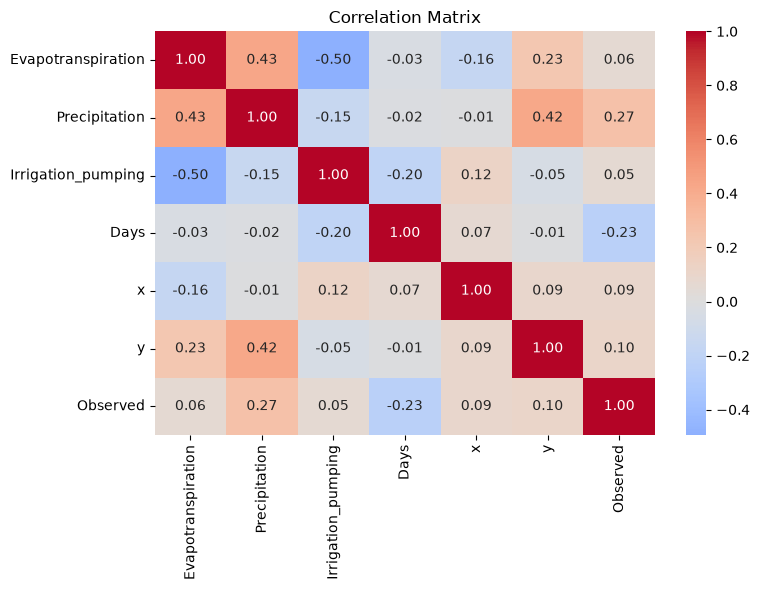

In [38]:
num_cols = ["Evapotranspiration", "Precipitation", "Irrigation_pumping", "Days", "x", "y", "Observed"]
corr = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

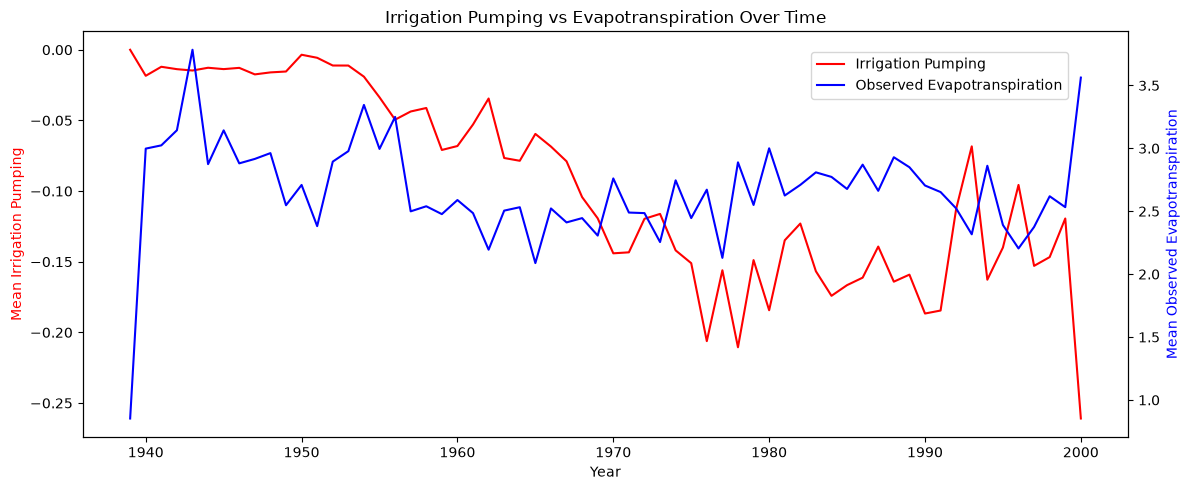

In [39]:
fig, ax1 = plt.subplots(figsize=(12, 5))

yearly = df.groupby("Year").agg(
    pump=("Irrigation_pumping", "mean"),
    obs=("Evapotranspiration", "mean")
)

ax1.plot(yearly.index, yearly["pump"], color="red", label="Irrigation Pumping")
ax1.set_xlabel("Year")
ax1.set_ylabel("Mean Irrigation Pumping", color="red")

ax2 = ax1.twinx()
ax2.plot(yearly.index, yearly["obs"], color="blue", label="Observed Evapotranspiration")
ax2.set_ylabel("Mean Observed Evapotranspiration", color="blue")

plt.title("Irrigation Pumping vs Evapotranspiration Over Time")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.9))
plt.tight_layout()
plt.show()

## Ethan's Section

In [40]:
df.isna().sum()

Date                  0
Segment_id            0
x                     0
y                     0
Evapotranspiration    0
Precipitation         0
Irrigation_pumping    0
Observed              0
Days                  0
DateTime              0
Year                  0
Month                 0
dtype: int64

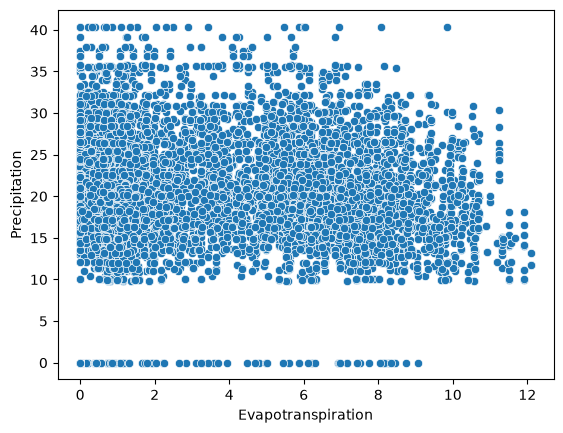

In [41]:
sns.scatterplot(data=df, x="Evapotranspiration", y="Precipitation")
plt.show()

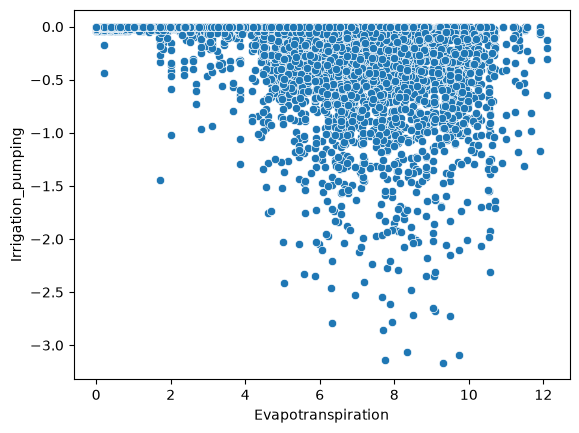

In [42]:
sns.scatterplot(data=df, x="Evapotranspiration", y="Irrigation_pumping")
plt.show()

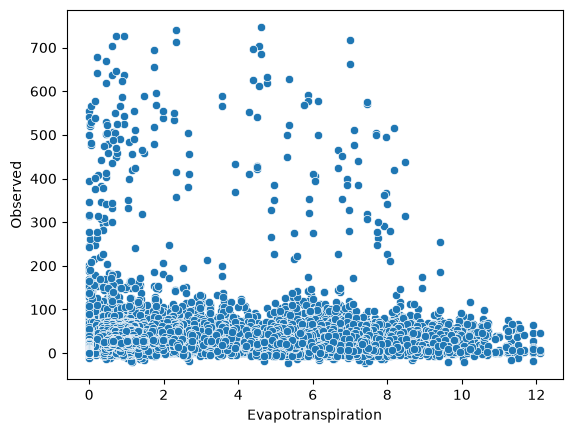

In [43]:
sns.scatterplot(data=df, x="Evapotranspiration", y="Observed")
plt.show()

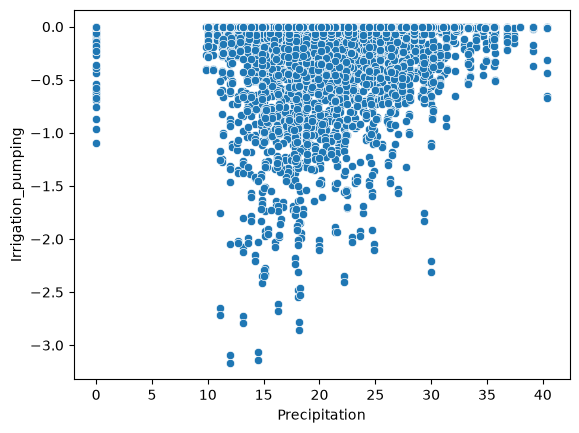

In [44]:
sns.scatterplot(data=df, x="Precipitation", y="Irrigation_pumping")
plt.show()

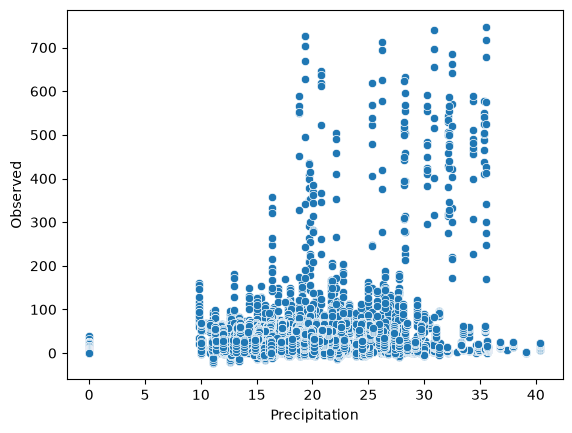

In [45]:
sns.scatterplot(data=df, x="Precipitation", y="Observed")
plt.show()

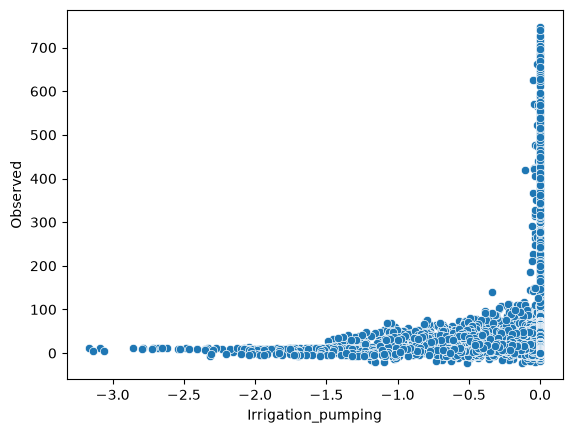

In [46]:
sns.scatterplot(data=df, x="Irrigation_pumping", y="Observed")
plt.show()

In [47]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# ---------------------------------------------------------
# 1. Feature Selection & Data Preparation
# ---------------------------------------------------------
features = ['Irrigation_pumping', 'Precipitation', 'Evapotranspiration']
target = 'Observed'

# Drop rows with missing values in target or features
model_df = df[features + [target]].dropna()

X = model_df[features]
y = model_df[target]

# Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ---------------------------------------------------------
# 2. Fit the Multiple Linear Regression Model
# ---------------------------------------------------------
reg = LinearRegression()
reg.fit(X_train, y_train)

# Evaluate predictions
y_pred = reg.predict(X_test)
print(f"Model R² Score: {r2_score(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}\n")

# Extract parameters
b0 = reg.intercept_
coefs = dict(zip(features, reg.coef_))
b_pump = coefs['Irrigation_pumping']
b_precip = coefs['Precipitation']
b_et = coefs['Evapotranspiration']

print("Fitted Coefficients:")
print(f"  Intercept (b0):           {b0:.4f}")
print(f"  Irrigation_pumping (b1):  {b_pump:.4f}")
print(f"  Precipitation (b2):       {b_precip:.4f}")
print(f"  Evapotranspiration (b3):  {b_et:.4f}\n")

# ---------------------------------------------------------
# 3. Dynamic Safe Pumping Threshold Function
# ---------------------------------------------------------
# Define a baseline "safe" baseflow level (e.g., historical 10th percentile)
safe_baseflow_default = y.quantile(0.10)

def get_max_safe_pumping(precip, et, safe_threshold=safe_baseflow_default):
    """
    Inverts the linear model:
    Observed = b0 + b1*Pumping + b2*Precip + b3*ET
    => Pumping_max = (safe_threshold - b0 - b2*Precip - b3*ET) / b1
    """
    if b_pump == 0:
        raise ValueError("Pumping coefficient is zero; cannot solve for threshold.")
    
    # Calculate maximum allowable pumping
    pumping_limit = (safe_threshold - b0 - (b_precip * precip) - (b_et * et)) / b_pump
    
    # Physical constraint: pumping cannot be negative
    return max(0.0, pumping_limit)

# ---------------------------------------------------------
# 4. Scenario Testing
# ---------------------------------------------------------
mean_precip = model_df['Precipitation'].mean()
low_precip = model_df['Precipitation'].quantile(0.10)
mean_et = model_df['Evapotranspiration'].mean()
high_et = model_df['Evapotranspiration'].quantile(0.90)

print(f"Reference Safe Baseflow Threshold: {safe_baseflow_default:.4f} m³/s\n")

print("Safe Pumping Thresholds under different conditions:")
print(f"  Average Weather (Mean P, Mean ET): "
      f"{get_max_safe_pumping(mean_precip, mean_et):.2f}")
print(f"  Drought / Dry Stress (Low P, High ET): "
      f"{get_max_safe_pumping(low_precip, high_et):.2f}")

Model R² Score: 0.0716
RMSE: 55.2546

Fitted Coefficients:
  Intercept (b0):           2.7997
  Irrigation_pumping (b1):  17.9895
  Precipitation (b2):       1.5838
  Evapotranspiration (b3):  -0.3660

Reference Safe Baseflow Threshold: 0.1220 m³/s

Safe Pumping Thresholds under different conditions:
  Average Weather (Mean P, Mean ET): 0.00
  Drought / Dry Stress (Low P, High ET): 0.01


In [48]:
## Attempt to improve results using a specific segment

# 1. Pick a specific segment (e.g., segment 98, or another critical segment)
selected_segment = 256
seg_df = df[df['Segment_id'] == selected_segment].copy()

features = ['Irrigation_pumping', 'Precipitation', 'Evapotranspiration']
target = 'Observed'

seg_clean = seg_df[features + [target]].dropna()

X = seg_clean[features]
y = seg_clean[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model_seg = LinearRegression()
model_seg.fit(X_train, y_train)

y_pred = model_seg.predict(X_test)
print(f"Segment {selected_segment} Model R²: {r2_score(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}\n")

b0 = model_seg.intercept_
b_pump = model_seg.coef_[0]
b_precip = model_seg.coef_[1]
b_et = model_seg.coef_[2]

print("Coefficients:")
print(f"  b0 (Intercept): {b0:.4f}")
print(f"  b1 (Pumping):   {b_pump:.4f}")
print(f"  b2 (Precip):    {b_precip:.4f}")
print(f"  b3 (ET):        {b_et:.4f}\n")

# Check if pumping is physically negative
if b_pump < 0:
    safe_flow = y.quantile(0.10)
    print(f"Safe Baseflow Target (10th percentile): {safe_flow:.4f} m³/s")

    def calc_safe_pumping(p, et):
        # Baseflow_safe = b0 + b1*P + b2*Precip + b3*ET
        # P_max = (Baseflow_safe - b0 - b2*Precip - b3*ET) / b1
        limit = (safe_flow - b0 - b_precip * p - b_et * et) / b_pump
        return max(0.0, limit)

    mean_p = seg_clean['Precipitation'].mean()
    dry_p = seg_clean['Precipitation'].quantile(0.10)
    mean_et = seg_clean['Evapotranspiration'].mean()
    high_et = seg_clean['Evapotranspiration'].quantile(0.90)

    print(f"Safe Pumping (Average Weather): {calc_safe_pumping(mean_p, mean_et):.2f}")
    print(f"Safe Pumping (Drought/Dry):     {calc_safe_pumping(dry_p, high_et):.2f}")
else:
    print("Warning: Pumping coefficient is still positive. Check lagged terms or seasonal effects.")

Segment 256 Model R²: 0.0793
RMSE: 202.4087

Coefficients:
  b0 (Intercept): 73.3133
  b1 (Pumping):   0.0000
  b2 (Precip):    11.2089
  b3 (ET):        3.9731



In [49]:
## Use OLS for better statistic reporting
import statsmodels.api as sm

# 1. Load data and select relevant columns
# Adjust column names to match the RRCA dataset
features = ['Irrigation_pumping', 'Precipitation', 'Evapotranspiration']
target = 'Observed'

# Drop missing values
df_clean = df[[target] + features].dropna()

X = df_clean[features]
y = df_clean[target]

# 2. Fit the Linear Regression model
X_with_const = sm.add_constant(X)
model = sm.OLS(y, X_with_const).fit()
print(model.summary())

# Extract coefficients
b0 = model.params['const']
b_pump = model.params['Irrigation_pumping']
b_precip = model.params['Precipitation']
b_et = model.params['Evapotranspiration']

# 3. Define the Safe Baseflow Threshold
# Example: 10th percentile of observed baseflow or an ecological limit
baseflow_safe = y.quantile(0.10) 

def calculate_max_pumping(precip, et, safe_level=baseflow_safe):
    """
    Computes max allowable pumping based on given weather conditions.
    """
    pumping_limit = (safe_level - b0 - (b_precip * precip) - (b_et * et)) / b_pump
    # Pumping cannot be negative
    return max(0, pumping_limit)

                            OLS Regression Results                            
Dep. Variable:               Observed   R-squared:                       0.083
Model:                            OLS   Adj. R-squared:                  0.082
Method:                 Least Squares   F-statistic:                     468.1
Date:                Thu, 29 Oct 2026   Prob (F-statistic):          2.91e-291
Time:                        21:23:55   Log-Likelihood:                -84285.
No. Observations:               15591   AIC:                         1.686e+05
Df Residuals:                   15587   BIC:                         1.686e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  3.2398      0

In [50]:
## Tried adding one-hot encoding and time lags to fix irrigation pumping issues

# -------------------------------------------------------------
# 1. Sort Data and Create Pumping Lags (Grouped by Segment)
# -------------------------------------------------------------
# Ensure the data is sorted chronologically per segment
df = df.sort_values(by=['Segment_id', 'Days']).copy()

# Compute 1-month and 2-month pumping lags within each segment
df['Pumping_lag1'] = df.groupby('Segment_id')['Irrigation_pumping'].shift(1)
df['Pumping_lag2'] = df.groupby('Segment_id')['Irrigation_pumping'].shift(2)

# -------------------------------------------------------------
# 2. Dummy Code the River Segments (One-Hot Encoding)
# -------------------------------------------------------------
# Create dummy variables for Segment_id (drop_first=True to avoid collinearity)
df_dummies = pd.get_dummies(df['Segment_id'], prefix='Seg', drop_first=True, dtype=float)

# Core hydrological features
hydro_features = [
    'Irrigation_pumping', 
    'Pumping_lag1', 
    'Pumping_lag2', 
    'Precipitation', 
    'Evapotranspiration'
]
target = 'Observed'

# Combine core features, segment dummy columns, and target
all_features = hydro_features + list(df_dummies.columns)
df_model = pd.concat([df[hydro_features + [target]], df_dummies], axis=1).dropna()

X = df_model[all_features]
y = df_model[target]

# -------------------------------------------------------------
# 3. Fit the Multiple Linear Regression Model
# -------------------------------------------------------------
X_with_const = sm.add_constant(X)
model = sm.OLS(y, X_with_const).fit()
print(model.summary())

# Extract core coefficients
b0 = model.params['const']
b_pump = model.params['Irrigation_pumping']
b_lag1 = model.params['Pumping_lag1']
b_lag2 = model.params['Pumping_lag2']
b_precip = model.params['Precipitation']
b_et = model.params['Evapotranspiration']

# Combined sustained pumping effect across the current and lagged months
b_total_pump = b_pump + b_lag1 + b_lag2

print(f"\nNet Sustained Pumping Effect (b_total_pump): {b_total_pump:.4f}")

# -------------------------------------------------------------
# 4. Invert Model for Dynamic Safe Pumping Threshold
# -------------------------------------------------------------
# Baseline 10th percentile of observed baseflow across the data
baseflow_safe = y.quantile(0.10)

def calculate_max_pumping(precip, et, segment_id=None, safe_level=baseflow_safe):
    """
    Computes maximum allowable sustained monthly pumping given weather conditions
    and a specific river reach (Segment_id).
    """
    if b_total_pump >= 0:
        print("Warning: Total pumping effect is non-negative; threshold cannot be solved physically.")
        return 0.0

    # Determine segment-specific baseline adjustment
    seg_dummy_col = f'Seg_{segment_id}'
    if segment_id is not None and seg_dummy_col in model.params:
        seg_effect = model.params[seg_dummy_col]
    else:
        # If reference segment (dropped dummy) or not specified, effect is 0
        seg_effect = 0.0

    # Effective intercept for this segment
    effective_b0 = b0 + seg_effect

    # Invert equation:
    # Baseflow = effective_b0 + b_total_pump * P + b_precip * Precip + b_et * ET
    # P_max = (safe_level - effective_b0 - b_precip * Precip - b_et * ET) / b_total_pump
    pumping_limit = (safe_level - effective_b0 - (b_precip * precip) - (b_et * et)) / b_total_pump

    return max(0.0, pumping_limit)

# -------------------------------------------------------------
# 5. Evaluate Scenarios
# -------------------------------------------------------------
mean_precip = df_model['Precipitation'].mean()
dry_precip = df_model['Precipitation'].quantile(0.10)
mean_et = df_model['Evapotranspiration'].mean()
high_et = df_model['Evapotranspiration'].quantile(0.90)

print("\n--- Example Safe Pumping Estimates ---")
print(f"Safe Pumping (Average Weather): {calculate_max_pumping(mean_precip, mean_et):.2f}")
print(f"Safe Pumping (Drought Scenario): {calculate_max_pumping(dry_precip, high_et):.2f}")

                            OLS Regression Results                            
Dep. Variable:               Observed   R-squared:                       0.817
Model:                            OLS   Adj. R-squared:                  0.816
Method:                 Least Squares   F-statistic:                     1497.
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:23:55   Log-Likelihood:                -71382.
No. Observations:               15507   AIC:                         1.429e+05
Df Residuals:                   15460   BIC:                         1.432e+05
Df Model:                          46                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  5.5682      1

### Major issues happening with 

In [51]:


# -------------------------------------------------------------------------
# 1. Select a Specific River Segment and Sort Chronologically
# -------------------------------------------------------------------------
# Choose a segment with substantial pumping and baseflow (e.g., segment 98)
selected_segment_id = 256

# Filter data for the chosen segment and sort chronologically by date/Days
seg_df = df[df['Segment_id'] == selected_segment_id].sort_values('Days').copy()

# -------------------------------------------------------------------------
# 2. Engineer Lagged & Cumulative Pumping Features
# -------------------------------------------------------------------------
# Groundwater depletion often acts with a lag:
# We include current month, 1-month lag, and a 3-month rolling average of pumping
seg_df['Pumping_lag1'] = seg_df['Irrigation_pumping'].shift(1)
seg_df['Pumping_rolling3'] = seg_df['Irrigation_pumping'].rolling(window=3).mean()

# -------------------------------------------------------------------------
# 3. Prepare Features and Fit OLS Regression
# -------------------------------------------------------------------------
features = [
    'Pumping_rolling3',       # Captures cumulative/seasonal pumping impact
    'Precipitation', 
    'Evapotranspiration'
]
target = 'Observed'

# Drop rows with NaN values created by shifts/rolling windows
clean_df = seg_df[features + [target]].dropna()

X = clean_df[features]
y = clean_df[target]

# Add constant and fit OLS model
X_with_const = sm.add_constant(X)
model = sm.OLS(y, X_with_const).fit()

print(f"=== OLS Regression Results for Segment {selected_segment_id} ===")
print(model.summary())

# -------------------------------------------------------------------------
# 4. Extract Parameters and Check Physical Validity
# -------------------------------------------------------------------------
b0 = model.params['const']
b_pump = model.params['Pumping_rolling3']
b_precip = model.params['Precipitation']
b_et = model.params['Evapotranspiration']

print("\n--- Extracted Model Parameters ---")
print(f"Intercept (b0):           {b0:.4f}")
print(f"Pumping Effect (b_pump):  {b_pump:.4f}")
print(f"Precipitation (b_precip): {b_precip:.4f}")
print(f"ET Effect (b_et):         {b_et:.4f}")

# -------------------------------------------------------------------------
# 5. Define and Calculate the Dynamic Safe Pumping Threshold
# -------------------------------------------------------------------------
# Define safe ecological baseflow threshold (e.g., 10th percentile for this segment)
safe_baseflow_threshold = y.quantile(0.10)
print(f"\nTarget Safe Baseflow Level (10th percentile): {safe_baseflow_threshold:.4f} m³/s")

def calculate_safe_pumping(precip, et, safe_level=safe_baseflow_threshold):
    """
    Inverts the linear regression:
    Observed = b0 + b_pump*Pumping + b_precip*Precip + b_et*ET
    => Pumping_limit = (safe_level - b0 - b_precip*Precip - b_et*ET) / b_pump
    """
    if b_pump >= 0:
        print("Warning: Pumping coefficient is non-negative; threshold cannot be solved physically.")
        return 0.0

    # Inverted model equation
    limit = (safe_level - b0 - (b_precip * precip) - (b_et * et)) / b_pump
    
    # Constrain pumping to be non-negative
    return max(0.0, limit)

# -------------------------------------------------------------------------
# 6. Evaluate Safe Pumping Quotas under Weather Scenarios
# -------------------------------------------------------------------------
mean_precip = clean_df['Precipitation'].mean()
drought_precip = clean_df['Precipitation'].quantile(0.10)
wet_precip = clean_df['Precipitation'].quantile(0.90)

mean_et = clean_df['Evapotranspiration'].mean()
high_et = clean_df['Evapotranspiration'].quantile(0.90)

print("\n=== Safe Irrigation Pumping Limits (m³/s or Volume Units) ===")
print(f"Average Conditions (Mean Precip, Mean ET):  {calculate_safe_pumping(mean_precip, mean_et):.2f}")
print(f"Drought Conditions (Low Precip, High ET):    {calculate_safe_pumping(drought_precip, high_et):.2f}")
print(f"Wet Season Conditions (High Precip, Mean ET): {calculate_safe_pumping(wet_precip, mean_et):.2f}")

=== OLS Regression Results for Segment 256 ===
                            OLS Regression Results                            
Dep. Variable:               Observed   R-squared:                       0.140
Model:                            OLS   Adj. R-squared:                  0.125
Method:                 Least Squares   F-statistic:                     9.266
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           0.000187
Time:                        21:23:55   Log-Likelihood:                -764.69
No. Observations:                 117   AIC:                             1535.
Df Residuals:                     114   BIC:                             1544.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------

### Finally did more exploration to find issue
Turned out the way irrigation pumping was represented in the data was backwards from what we expected

In [52]:
# Find segments with the highest total/mean irrigation pumping
pumping_by_seg = df.groupby('Segment_id')['Irrigation_pumping'].agg(['count', 'mean', 'max', 'std'])
pumping_by_seg = pumping_by_seg.sort_values(by='mean', ascending=False)
print("Top 10 Segments with Active Irrigation Pumping:")
print(pumping_by_seg.head(10))

Top 10 Segments with Active Irrigation Pumping:
            count  mean  max  std
Segment_id                       
51            495   0.0  0.0  0.0
56            653   0.0  0.0  0.0
196           656   0.0  0.0  0.0
256           119   0.0  0.0  0.0
189           718   0.0  0.0  0.0
186           108   0.0  0.0  0.0
145           399   0.0  0.0  0.0
146           459   0.0  0.0  0.0
123             8   0.0  0.0  0.0
98            315   0.0  0.0  0.0


In [53]:
# 1. Check overall pumping distribution
print("Overall dataset pumping summary:")
print(df['Irrigation_pumping'].describe())

# 2. Filter for segments that actually have non-zero pumping
pumping_nonzero = df[df['Irrigation_pumping'] > 0]
print(f"\nTotal rows with pumping > 0: {len(pumping_nonzero)} out of {len(df)}")

# 3. List the segments that actually pump water
active_pump_segments = pumping_nonzero.groupby('Segment_id')['Irrigation_pumping'].agg(['count', 'mean', 'max', 'std'])
active_pump_segments = active_pump_segments.sort_values(by='max', ascending=False)
print("\nSegments with Actual Non-Zero Pumping:")
print(active_pump_segments)

Overall dataset pumping summary:
count    15591.000000
mean        -0.090713
std          0.273726
min         -3.164700
25%         -0.012000
50%          0.000000
75%          0.000000
max          0.000000
Name: Irrigation_pumping, dtype: float64

Total rows with pumping > 0: 0 out of 15591

Segments with Actual Non-Zero Pumping:
Empty DataFrame
Columns: [count, mean, max, std]
Index: []


## Found issue: Model was treating irrigation pumping as water added to the river


In [54]:
# -------------------------------------------------------------------------
# 1. Prepare Features & Convert Pumping to Positive Extraction Rate
# -------------------------------------------------------------------------

# Negate pumping so positive values mean more water extracted
df['Pumping_rate'] = -df['Irrigation_pumping']

# One-hot encode Segment_id to account for baseline reach flow differences
df_dummies = pd.get_dummies(df['Segment_id'], prefix='Seg', drop_first=True, dtype=float)

hydro_features = ['Pumping_rate', 'Precipitation', 'Evapotranspiration']
target = 'Observed'
all_features = hydro_features + list(df_dummies.columns)

df_model = pd.concat([df[hydro_features + [target]], df_dummies], axis=1).dropna()

X = df_model[all_features]
y = df_model[target]

# -------------------------------------------------------------------------
# 2. Fit the Multiple Linear Regression Model
# -------------------------------------------------------------------------
X_with_const = sm.add_constant(X)
model = sm.OLS(y, X_with_const).fit()

# Extract model parameters
b0 = model.params['const']
b_pump = model.params['Pumping_rate']
b_precip = model.params['Precipitation']
b_et = model.params['Evapotranspiration']

# -------------------------------------------------------------------------
# 3. Formatted Model Display because the normal summary shows every single river segment (Standard statsmodels Layout)
# -------------------------------------------------------------------------
print("=" * 80)
print(f"{'OLS Regression Results (Core Hydrological Drivers)':^80}")
print("=" * 80)
print(f"Dep. Variable:      {target:<18} R-squared:                     {model.rsquared:>8.4f}")
print(f"Model:              OLS                 Adj. R-squared:            {model.rsquared_adj:>8.4f}")
print(f"No. Observations:   {int(model.nobs):<18} F-statistic:               {model.fvalue:>8.2f}")
print(f"Df Residuals:       {int(model.df_resid):<18} Prob (F-statistic):         {model.f_pvalue:>8.2e}")
print(f"Covariance Type:    nonrobust           Durbin-Watson:             {sm.stats.stattools.durbin_watson(model.resid):>8.4f}")
print("=" * 80)
print(f"{'Variable':<22}{'coef':>10}{'std err':>10}{'t':>9}{'P>|t|':>9}{'[0.025':>10}{'0.975]':>10}")
print("-" * 80)

# Display core hydrological parameters
core_vars = ['const', 'Pumping_rate', 'Precipitation', 'Evapotranspiration']
for var in core_vars:
    coef = model.params[var]
    stderr = model.bse[var]
    tval = model.tvalues[var]
    pval = model.pvalues[var]
    ci_low, ci_high = model.conf_int().loc[var]
    print(f"{var:<22}{coef:>10.4f}{stderr:>10.4f}{tval:>9.3f}{pval:>9.3f}{ci_low:>10.3f}{ci_high:>10.3f}")

print("-" * 80)
print(f"* Note: Model includes {len(df_dummies.columns)} segment fixed effects (omitted for brevity).")
print("=" * 80)

# -------------------------------------------------------------------------
# 4. Safe Pumping Threshold Function
# -------------------------------------------------------------------------
safe_baseflow = y.quantile(0.10)

def calculate_max_safe_pumping(precip, et, segment_id=None, safe_level=safe_baseflow):
    """
    Inverts the linear model:
    Observed = b0 + b_seg + b_pump*P_rate + b_precip*Precip + b_et*ET
    => P_rate_max = (safe_level - (b0 + b_seg) - b_precip*Precip - b_et*ET) / b_pump
    """
    seg_effect = 0.0
    if segment_id is not None:
        col = f'Seg_{segment_id}'
        if col in model.params:
            seg_effect = model.params[col]
            
    effective_b0 = b0 + seg_effect
    flow_without_pumping = effective_b0 + (b_precip * precip) + (b_et * et)
    
    # Allowable pumping is the surplus flow divided by the depletion per unit pumping
    pumping_limit = (safe_level - flow_without_pumping) / b_pump
    return max(0.0, pumping_limit)

# -------------------------------------------------------------------------
# 5. Scenario Testing & Detailed Explanations
# -------------------------------------------------------------------------
mean_p = df_model['Precipitation'].mean()
dry_p = df_model['Precipitation'].quantile(0.10)
wet_p = df_model['Precipitation'].quantile(0.90)

mean_et = df_model['Evapotranspiration'].mean()
high_et = df_model['Evapotranspiration'].quantile(0.90)

allow_avg = calculate_max_safe_pumping(mean_p, mean_et)
allow_dry = calculate_max_safe_pumping(dry_p, high_et)
allow_wet = calculate_max_safe_pumping(wet_p, mean_et)

print("\n" + "=" * 80)
print(f"{'Dynamic Safe Pumping Analysis':^80}")
print("=" * 80)
print(f"Reference Safe Baseflow Threshold (10th percentile): {safe_baseflow:.4f} m³/s\n")
print(f"{'Climate Scenario':<35} | {'Precip':>8} | {'ET':>8} | {'Safe Pumping Limit':>20}")
print("-" * 80)
print(f"{'Drought (Low Precip, High ET)':<35} | {dry_p:>8.2f} | {high_et:>8.2f} | {allow_dry:>20.2f}")
print(f"{'Average (Mean Precip, Mean ET)':<35} | {mean_p:>8.2f} | {mean_et:>8.2f} | {allow_avg:>20.2f}")
print(f"{'Wet Season (High Precip, Mean ET)':<35} | {wet_p:>8.2f} | {mean_et:>8.2f} | {allow_wet:>20.2f}")
print("=" * 80)

# Summary of the results
print("\n--- Practical Interpretation of Results ---")
print(f"1. Model Fit: The model explains {model.rsquared*100:.1f}% of baseflow variation across the basin.")
print(f"2. Pumping Impact: Every 1.0 unit of irrigation pumping reduces stream baseflow by {abs(b_pump):.2f} m³/s.")
print(f"3. Weather Impact: Rain increases baseflow by +{b_precip:.2f} m³/s per unit, while ET reduces it by -{abs(b_et):.2f} m³/s per unit.")
print(f"4. Policy Recommendation:")
print(f"   - Under Drought ({allow_dry:.2f} units allowed): River is at risk; shut off irrigation extraction entirely.")
print(f"   - Under Normal weather ({allow_avg:.2f} units allowed): Moderate extraction is safe.")
print(f"   - Under Wet conditions ({allow_wet:.2f} units allowed): High rainfall allows extraction up to {allow_wet:.2f} units.")

               OLS Regression Results (Core Hydrological Drivers)               
Dep. Variable:      Observed           R-squared:                       0.8063
Model:              OLS                 Adj. R-squared:              0.8057
No. Observations:   15591              F-statistic:                1470.71
Df Residuals:       15546              Prob (F-statistic):         0.00e+00
Covariance Type:    nonrobust           Durbin-Watson:               0.4570
Variable                    coef   std err        t    P>|t|    [0.025    0.975]
--------------------------------------------------------------------------------
const                     3.9242    1.7386    2.257    0.024     0.516     7.332
Pumping_rate             -4.6104    0.8886   -5.189    0.000    -6.352    -2.869
Precipitation             0.4903    0.0390   12.563    0.000     0.414     0.567
Evapotranspiration       -0.8705    0.0838  -10.392    0.000    -1.035    -0.706
---------------------------------------------------

C:\Users\Bates\AppData\Local\Temp\ipykernel_24388\687819683.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.bxp(


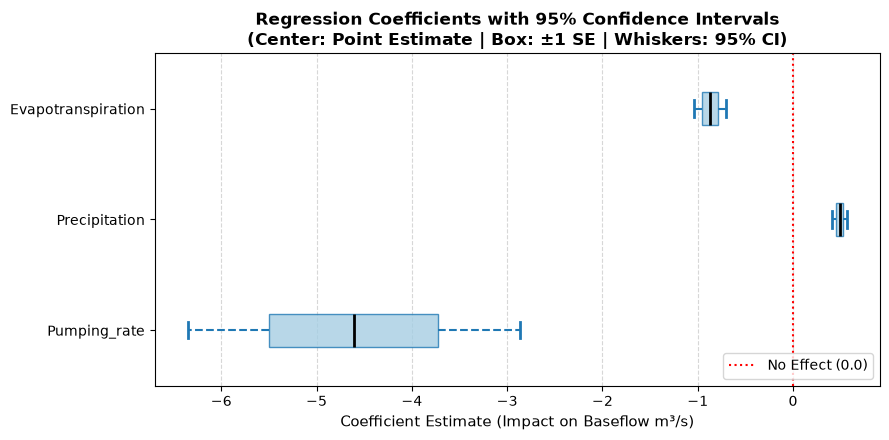

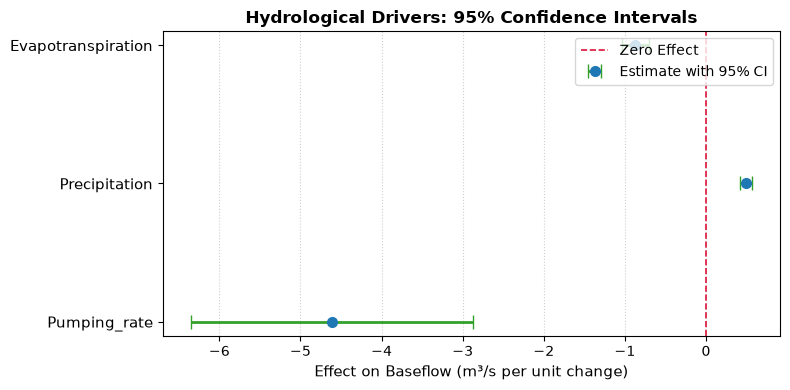

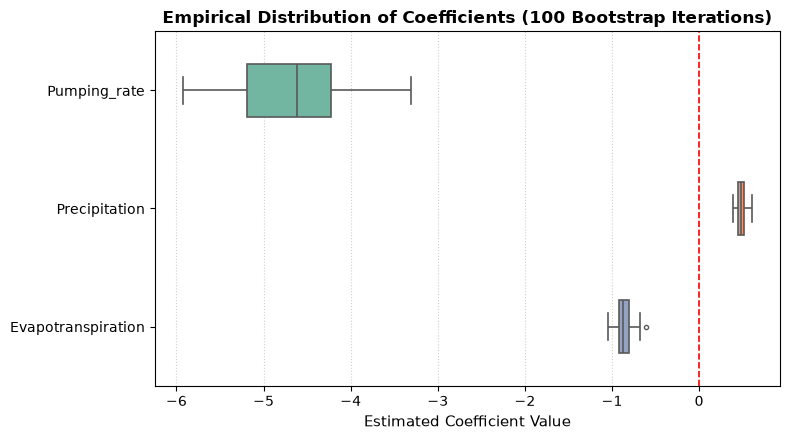

In [55]:
# =========================================================================
# 1. Prepare Data from OLS Model
# =========================================================================
# Focus on the core hydrological drivers
core_vars = ['Pumping_rate', 'Precipitation', 'Evapotranspiration']

# Extract estimates, standard errors, and 95% confidence intervals
coef_df = pd.DataFrame(
    {
        'Variable': core_vars,
        'coef': [model.params[v] for v in core_vars],
        'std_err': [model.bse[v] for v in core_vars],
        'ci_lower': [model.conf_int().loc[v, 0] for v in core_vars],
        'ci_upper': [model.conf_int().loc[v, 1] for v in core_vars],
    }
)

# =========================================================================
# Option A: Box & Whisker Style for Confidence Intervals
# (Box = ±1 Std Error / 68% CI, Whiskers = 95% Confidence Interval)
# =========================================================================
fig, ax = plt.subplots(figsize=(9, 4.5))

box_stats = []
for _, row in coef_df.iterrows():
    box_stats.append(
        {
            'med': row['coef'],  # Point estimate
            'q1': row['coef'] - row['std_err'],  # Lower bound of 1 SE
            'q3': row['coef'] + row['std_err'],  # Upper bound of 1 SE
            'whislo': row['ci_lower'],  # 95% CI Lower Bound
            'whishi': row['ci_upper'],  # 95% CI Upper Bound
            'fliers': [],  # No outliers
            'label': row['Variable'],
        }
    )

# Draw custom boxplot using bxp
bp = ax.bxp(
    box_stats,
    vert=False,
    patch_artist=True,
    showmeans=False,
    medianprops=dict(color='black', linewidth=2),
    boxprops=dict(facecolor='#a6cee3', edgecolor='#1f78b4', alpha=0.8),
    whiskerprops=dict(color='#1f78b4', linewidth=1.5, linestyle='--'),
    capprops=dict(color='#1f78b4', linewidth=2),
)

# Reference dashed line at zero (significance threshold)
ax.axvline(0, color='red', linestyle=':', linewidth=1.5, label='No Effect (0.0)')

ax.set_title(
    'Regression Coefficients with 95% Confidence Intervals\n'
    '(Center: Point Estimate | Box: ±1 SE | Whiskers: 95% CI)',
    fontsize=12,
    weight='bold',
)
ax.set_xlabel('Coefficient Estimate (Impact on Baseflow m³/s)', fontsize=11)
ax.grid(axis='x', linestyle='--', alpha=0.5)
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

# =========================================================================
# Option B: Standard Coefficient Forest Plot (Recommended for OLS)
# =========================================================================
fig, ax = plt.subplots(figsize=(8, 4))

y_positions = np.arange(len(coef_df))
errors = [
    coef_df['coef'] - coef_df['ci_lower'],
    coef_df['ci_upper'] - coef_df['coef'],
]

# Plot horizontal error bars representing the 95% CI
ax.errorbar(
    coef_df['coef'],
    y_positions,
    xerr=errors,
    fmt='o',
    color='#1f78b4',
    ecolor='#33a02c',
    elinewidth=2,
    capsize=5,
    markersize=7,
    label='Estimate with 95% CI',
)

# Reference line at zero
ax.axvline(0, color='crimson', linestyle='--', linewidth=1.2, label='Zero Effect')

ax.set_yticks(y_positions)
ax.set_yticklabels(coef_df['Variable'], fontsize=11)
ax.set_xlabel('Effect on Baseflow (m³/s per unit change)', fontsize=11)
ax.set_title('Hydrological Drivers: 95% Confidence Intervals', fontsize=12, weight='bold')
ax.grid(axis='x', linestyle=':', alpha=0.6)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

# =========================================================================
# Option C: Empirical Bootstrap Boxplot
# (Generates actual empirical box & whisker plots across 100 resamples)
# =========================================================================
np.random.seed(42)
n_bootstraps = 100
boot_coefs = []

for _ in range(n_bootstraps):
    sample = df_model.sample(frac=1.0, replace=True)
    X_sample = sm.add_constant(sample[all_features])
    y_sample = sample[target]
    res = sm.OLS(y_sample, X_sample).fit()
    boot_coefs.append({v: res.params[v] for v in core_vars})

boot_df = pd.DataFrame(boot_coefs)

plt.figure(figsize=(8, 4.5))
sns.boxplot(
    data=boot_df,
    orient='h',
    palette='Set2',
    fliersize=3,
    linewidth=1.2,
    width=0.45,
)
plt.axvline(0, color='red', linestyle='--', linewidth=1.2)
plt.title('Empirical Distribution of Coefficients (100 Bootstrap Iterations)', fontsize=12, weight='bold')
plt.xlabel('Estimated Coefficient Value', fontsize=11)
plt.grid(axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

                Scikit-Learn Multiple Linear Regression Results                 
Train R² Score:       0.8040      | Test R² Score:      0.8125
Test RMSE:           25.8495 m³/s | Test MAE:           8.5500 m³/s
--------------------------------------------------------------------------------
Variable                     Coefficient             Hydrological Interpretation
--------------------------------------------------------------------------------
Intercept (b0)                    4.7168     Baseline flow for reference segment
Pumping_rate                     -4.0012        Flow loss (m³/s) per unit pumped
Precipitation                     0.4700      Recharge gain (m³/s) per unit rain
Evapotranspiration               -0.9396     Evaporative loss (m³/s) per unit ET

             Safe Pumping Thresholds (Inverted Scikit-Learn Model)              
Safe Baseflow Cutoff (10th percentile): 0.1220 m³/s

Climate Scenario                    |   Precip |       ET |   Safe Pumping Limit
-----

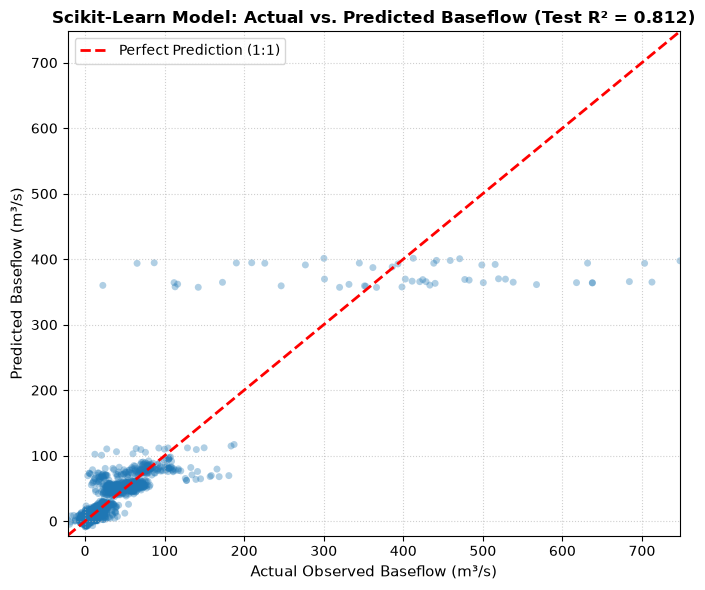

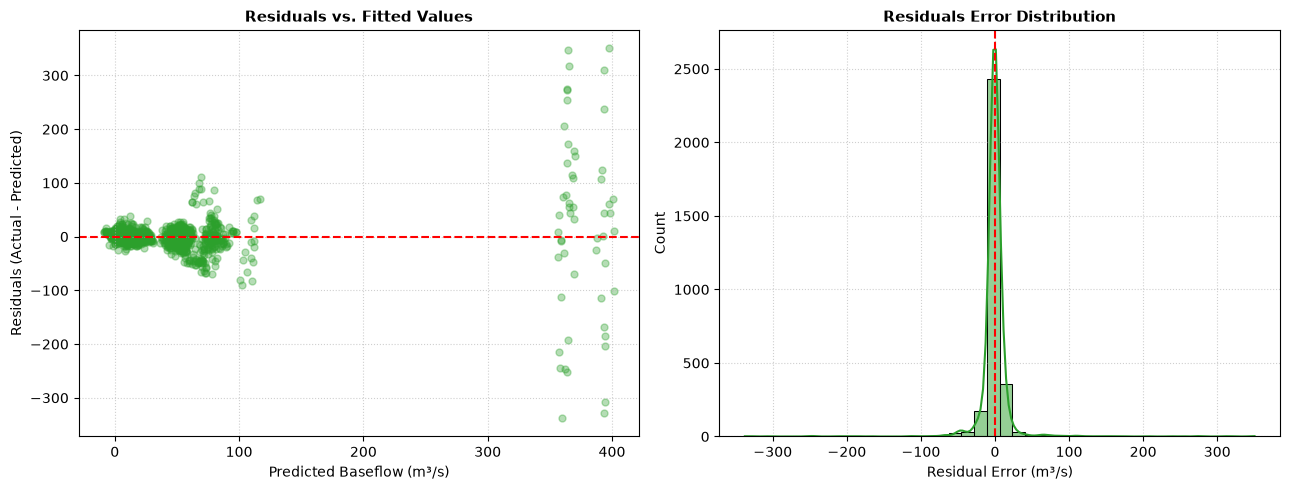

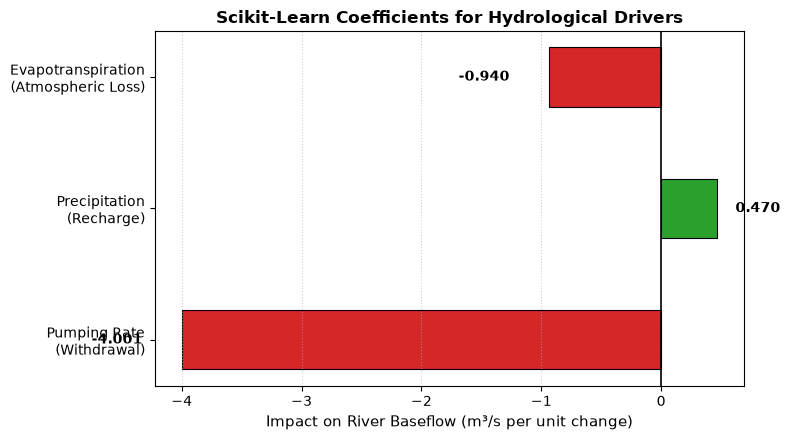

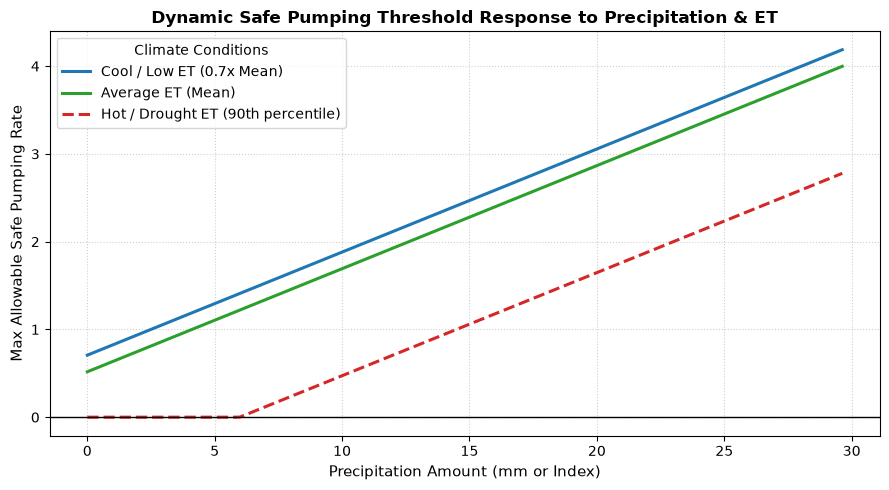

In [56]:
# =========================================================================
# 1. Feature Engineering & Preparation
# =========================================================================
# Convert extraction to positive volume: higher value = more water pumped
df['Pumping_rate'] = -df['Irrigation_pumping']

# One-hot encode Segment_id to account for spatial stream size differences
df_dummies = pd.get_dummies(df['Segment_id'], prefix='Seg', drop_first=True, dtype=float)

hydro_features = ['Pumping_rate', 'Precipitation', 'Evapotranspiration']
target = 'Observed'
all_features = hydro_features + list(df_dummies.columns)

df_model = pd.concat([df[hydro_features + [target]], df_dummies], axis=1).dropna()

X = df_model[all_features]
y = df_model[target]

# 80/20 Train-Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# =========================================================================
# 2. Fit the Scikit-Learn LinearRegression Model
# =========================================================================
sklearn_model = LinearRegression(fit_intercept=True)
sklearn_model.fit(X_train, y_train)

# Predictions & performance metrics
y_train_pred = sklearn_model.predict(X_train)
y_test_pred = sklearn_model.predict(X_test)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_mae = mean_absolute_error(y_test, y_test_pred)

# Extract core parameters
b0 = sklearn_model.intercept_
coef_dict = dict(zip(all_features, sklearn_model.coef_))
b_pump = coef_dict['Pumping_rate']
b_precip = coef_dict['Precipitation']
b_et = coef_dict['Evapotranspiration']

# =========================================================================
# 3. Model Results Display
# =========================================================================
print("=" * 80)
print(f"{'Scikit-Learn Multiple Linear Regression Results':^80}")
print("=" * 80)
print(f"Train R² Score:     {train_r2:>8.4f}      | Test R² Score:    {test_r2:>8.4f}")
print(f"Test RMSE:          {test_rmse:>8.4f} m³/s | Test MAE:         {test_mae:>8.4f} m³/s")
print("-" * 80)
print(f"{'Variable':<25}{'Coefficient':>15}{'Hydrological Interpretation':>40}")
print("-" * 80)
print(f"{'Intercept (b0)':<25}{b0:>15.4f}{'Baseline flow for reference segment':>40}")
print(f"{'Pumping_rate':<25}{b_pump:>15.4f}{'Flow loss (m³/s) per unit pumped':>40}")
print(f"{'Precipitation':<25}{b_precip:>15.4f}{'Recharge gain (m³/s) per unit rain':>40}")
print(f"{'Evapotranspiration':<25}{b_et:>15.4f}{'Evaporative loss (m³/s) per unit ET':>40}")
print("=" * 80)

# =========================================================================
# 4. Invert Model for Dynamic Safe Pumping Threshold
# =========================================================================
safe_baseflow = y.quantile(0.10)

def calculate_max_safe_pumping(precip, et, segment_id=None, safe_level=safe_baseflow):
    """
    Inverts the linear model:
    Observed = b0 + b_seg + b_pump*P_rate + b_precip*Precip + b_et*ET
    => P_rate_max = (safe_level - (b0 + b_seg) - b_precip*Precip - b_et*ET) / b_pump
    """
    seg_effect = 0.0
    if segment_id is not None:
        seg_col = f'Seg_{segment_id}'
        if seg_col in coef_dict:
            seg_effect = coef_dict[seg_col]

    effective_b0 = b0 + seg_effect
    flow_without_pumping = effective_b0 + (b_precip * precip) + (b_et * et)
    
    # Invert linear relation
    pumping_limit = (safe_level - flow_without_pumping) / b_pump
    return max(0.0, pumping_limit)

# Weather scenarios
mean_p = df_model['Precipitation'].mean()
dry_p = df_model['Precipitation'].quantile(0.10)
wet_p = df_model['Precipitation'].quantile(0.90)

mean_et = df_model['Evapotranspiration'].mean()
high_et = df_model['Evapotranspiration'].quantile(0.90)

allow_avg = calculate_max_safe_pumping(mean_p, mean_et)
allow_dry = calculate_max_safe_pumping(dry_p, high_et)
allow_wet = calculate_max_safe_pumping(wet_p, mean_et)

print("\n" + "=" * 80)
print(f"{'Safe Pumping Thresholds (Inverted Scikit-Learn Model)':^80}")
print("=" * 80)
print(f"Safe Baseflow Cutoff (10th percentile): {safe_baseflow:.4f} m³/s\n")
print(f"{'Climate Scenario':<35} | {'Precip':>8} | {'ET':>8} | {'Safe Pumping Limit':>20}")
print("-" * 80)
print(f"{'Drought (Low Precip, High ET)':<35} | {dry_p:>8.2f} | {high_et:>8.2f} | {allow_dry:>20.2f}")
print(f"{'Average (Mean Precip, Mean ET)':<35} | {mean_p:>8.2f} | {mean_et:>8.2f} | {allow_avg:>20.2f}")
print(f"{'Wet Season (High Precip, Mean ET)':<35} | {wet_p:>8.2f} | {mean_et:>8.2f} | {allow_wet:>20.2f}")
print("=" * 80)

# =========================================================================
# 5. Visualizations
# =========================================================================

# -------------------------------------------------------------------------
# Plot 1: Actual vs. Predicted Baseflow
# -------------------------------------------------------------------------
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_test_pred, alpha=0.35, color='#1f77b4', edgecolors='none', s=25)
# 45-degree reference line
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction (1:1)')

plt.title(f'Scikit-Learn Model: Actual vs. Predicted Baseflow (Test R² = {test_r2:.3f})', fontsize=12, weight='bold')
plt.xlabel('Actual Observed Baseflow (m³/s)', fontsize=11)
plt.ylabel('Predicted Baseflow (m³/s)', fontsize=11)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# Plot 2: Residual Analysis Plot
# -------------------------------------------------------------------------
residuals = y_test - y_test_pred

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Residuals vs. Fitted
ax1.scatter(y_test_pred, residuals, alpha=0.35, color='#2ca02c', s=25)
ax1.axhline(0, color='red', linestyle='--', lw=1.5)
ax1.set_title('Residuals vs. Fitted Values', fontsize=11, weight='bold')
ax1.set_xlabel('Predicted Baseflow (m³/s)', fontsize=10)
ax1.set_ylabel('Residuals (Actual - Predicted)', fontsize=10)
ax1.grid(True, linestyle=':', alpha=0.6)

# Residual Distribution Histogram
sns.histplot(residuals, kde=True, ax=ax2, color='#2ca02c', bins=40)
ax2.axvline(0, color='red', linestyle='--', lw=1.5)
ax2.set_title('Residuals Error Distribution', fontsize=11, weight='bold')
ax2.set_xlabel('Residual Error (m³/s)', fontsize=10)
ax2.set_ylabel('Count', fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# Plot 3: Core Regression Coefficients
# -------------------------------------------------------------------------
core_labels = ['Pumping Rate\n(Withdrawal)', 'Precipitation\n(Recharge)', 'Evapotranspiration\n(Atmospheric Loss)']
core_coef_values = [b_pump, b_precip, b_et]
colors = ['#d62728' if c < 0 else '#2ca02c' for c in core_coef_values]

plt.figure(figsize=(8, 4.5))
bars = plt.barh(core_labels, core_coef_values, color=colors, height=0.45, edgecolor='black', linewidth=0.8)
plt.axvline(0, color='black', linestyle='-', lw=1.2)

# Add value labels to the ends of the bars
for bar in bars:
    width = bar.get_width()
    offset = 0.15 if width >= 0 else -0.75
    plt.text(width + offset, bar.get_y() + bar.get_height()/2, f'{width:.3f}', 
             va='center', fontsize=10, weight='bold')

plt.title('Scikit-Learn Coefficients for Hydrological Drivers', fontsize=12, weight='bold')
plt.xlabel('Impact on River Baseflow (m³/s per unit change)', fontsize=11)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# Plot 4: Dynamic Safe Pumping Response Curve across Climate Scenarios
# -------------------------------------------------------------------------
p_range = np.linspace(0, df_model['Precipitation'].quantile(0.95), 100)

p_allow_low_et = [calculate_max_safe_pumping(p, mean_et * 0.7) for p in p_range]
p_allow_avg_et = [calculate_max_safe_pumping(p, mean_et) for p in p_range]
p_allow_high_et = [calculate_max_safe_pumping(p, high_et) for p in p_range]

plt.figure(figsize=(9, 5))
plt.plot(p_range, p_allow_low_et, label='Cool / Low ET (0.7x Mean)', color='#1f77b4', lw=2.2)
plt.plot(p_range, p_allow_avg_et, label='Average ET (Mean)', color='#2ca02c', lw=2.2)
plt.plot(p_range, p_allow_high_et, label='Hot / Drought ET (90th percentile)', color='#d62728', lw=2.2, linestyle='--')

plt.axhline(0, color='black', lw=1)
plt.title('Dynamic Safe Pumping Threshold Response to Precipitation & ET', fontsize=12, weight='bold')
plt.xlabel('Precipitation Amount (mm or Index)', fontsize=11)
plt.ylabel('Max Allowable Safe Pumping Rate', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(title='Climate Conditions', loc='upper left')
plt.tight_layout()
plt.show()